In [1]:
from pathlib import Path
import sys
import numpy as np

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"


train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]


SEED = 42
import torch
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
from src.models.mlp import MLP
from src.evaluation.metrics import ClassificationMetrics
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
from src.preprocessing.scaler import split_val, scale_flat

In [3]:
X_train, X_val, y_train, y_val = split_val(X=X_train,y=y_train, val_size=0.1, seed=SEED)
X_train, X_val, X_test,tools = scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode="standard")
print(f'Train: {len(X_train)}, Test: {len(X_test)}, Val: {len(X_val)}')

Global Mean: 0.1307, Global Std: 0.3082
Train: 54000, Test: 10000, Val: 6000


# MLP - Hyperparameter Tuning and Evaluation

## Mục tiêu

Thực hiện tinh chỉnh siêu tham số cho mô hình Multi-Layer Perceptron
(MLP) trên tập dữ liệu MNIST.

Quá trình tinh chỉnh gồm ba giai đoạn:

1. Learning Rate và Momentum.
2. Kiến trúc mạng (Architecture).
3. Dropout và L2 Regularization.

Sau khi tuning, so sánh mô hình Baseline và Tuned MLP
thông qua Accuracy, Macro F1, Learning Curves,
Confusion Matrix và Per-Class Recall.

Tất cả hyperparameters được lựa chọn dựa trên validation set.

In [4]:
# set up
SEED = 42
LABELS = np.arange(10)

BATCH_SIZE = 128
PATIENCE = 6

# Baseline MLP
MLP_BASELINE = {
    "sizes": [784, 256, 128, 10],
    "lr": 0.05,
    "momentum": 0.9,
    "p_drop": 0.0,
    "weight_decay": 0.0
}

# Stage 1: Learning Rate và Momentum
LR_GRID = [0.01, 0.03, 0.05, 0.1]
MOMENTUM_GRID = [0.0, 0.5, 0.9]

# Stage 2: Kiến trúc mạng
ARCH_GRID = [
    [784, 500, 10],
    [784, 128, 10],
    [784, 256, 10],
    [784, 256, 128, 10]
]

# Stage 3: Regularization
DROPOUT_GRID = [0.0, 0.2, 0.4]
WEIGHT_DECAY_GRID = [0.0, 1e-4, 1e-3]

# Số epochs cho mỗi giai đoạn
EPOCHS_OPTIMIZER = 8
EPOCHS_ARCH = 10
EPOCHS_REG = 30
EPOCHS_FINAL = 40

sns.set_theme(style="whitegrid")

## Hàm huấn luyện MLP

- Trả về model, history và training time.

Mỗi lần gọi đều tạo mô hình mới để các cấu hình
không sử dụng lại trọng số từ lần huấn luyện trước.

In [ ]:
def train_mlp(
    sizes,
    lr,
    momentum,
    p_drop=0.0,
    weight_decay=0.0,
    epochs=10,
    patience=None
):
    """Khởi tạo và huấn luyện một mô hình MLP."""

    model = MLP(
        sizes=sizes,
        activation="relu",
        p_drop=p_drop,
        init="he",
        seed=SEED
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_train, # train đã đc khai báo toàn cục
        y_train,
        epochs=epochs,
        batch_size=BATCH_SIZE,
        lr=lr,
        momentum=momentum,
        weight_decay=weight_decay,
        validation_data=(X_val, y_val),
        patience=patience,
        seed=SEED,
        verbose=False
    )

    train_time = time.perf_counter() - start_time

    return model, history, train_time

## 1. Tuning Learning Rate và Momentum

Mục tiêu: Khảo sát ảnh hưởng của Learning Rate và
Momentum đến khả năng học của MLP.

Learning Rate:
- 0.01
- 0.03
- 0.05
- 0.1

Momentum:
- 0.0
- 0.5
- 0.9

Tổng cộng: 4 × 3 = 12 cấu hình.

Giữ cố định kiến trúc 784-256-128-10,
ReLU, He Initialization, Batch Size = 128.

Mỗi cấu hình được huấn luyện 8 epochs để
so sánh khả năng học ban đầu.

Tiêu chí lựa chọn: Validation Accuracy.

In [6]:
optimizer_results = []

for momentum in MOMENTUM_GRID:
    for lr in LR_GRID:

        model, history, train_time = train_mlp(
            sizes=MLP_BASELINE["sizes"],
            lr=lr,
            momentum=momentum,
            epochs=EPOCHS_OPTIMIZER
        )

        val_acc = history["val_acc"][-1]
        val_loss = history["val_loss"][-1]

        # Bỏ qua cấu hình có loss không hợp lệ
        if not np.isfinite(val_loss):
            val_acc = np.nan
            val_loss = np.nan

        optimizer_results.append({
            "lr": lr,
            "momentum": momentum,
            "val_accuracy": val_acc,
            "val_loss": val_loss,
            "train_time": train_time
        })

        print(
            f"lr={lr:<5} | "
            f"momentum={momentum:<3} | "
            f"Val Acc={val_acc:.4f}"
        )


optimizer_df = pd.DataFrame(optimizer_results)

valid_optimizer_df = optimizer_df.dropna(
    subset=["val_accuracy", "val_loss"]
)

if valid_optimizer_df.empty:
    raise RuntimeError("Không có cấu hình optimizer hợp lệ.")

best_optimizer = valid_optimizer_df.sort_values(
    by=["val_accuracy", "val_loss"],
    ascending=[False, True]
).iloc[0]

best_lr = float(best_optimizer["lr"])
best_momentum = float(best_optimizer["momentum"])

print("\n=== BEST OPTIMIZER ===")
print(f"Learning Rate: {best_lr}")
print(f"Momentum: {best_momentum}")
print(f"Validation Accuracy: {best_optimizer['val_accuracy']:.4f}")

lr=0.01  | momentum=0.0 | Val Acc=0.9550
lr=0.03  | momentum=0.0 | Val Acc=0.9672
lr=0.05  | momentum=0.0 | Val Acc=0.9723
lr=0.1   | momentum=0.0 | Val Acc=0.9737
lr=0.01  | momentum=0.5 | Val Acc=0.9642
lr=0.03  | momentum=0.5 | Val Acc=0.9710
lr=0.05  | momentum=0.5 | Val Acc=0.9743
lr=0.1   | momentum=0.5 | Val Acc=0.9775
lr=0.01  | momentum=0.9 | Val Acc=0.9748
lr=0.03  | momentum=0.9 | Val Acc=0.9777
lr=0.05  | momentum=0.9 | Val Acc=0.9787
lr=0.1   | momentum=0.9 | Val Acc=0.9745

=== BEST OPTIMIZER ===
Learning Rate: 0.05
Momentum: 0.9
Validation Accuracy: 0.9787


### Biểu đồ 1. Learning Rate × Momentum Heatmap

Sử dụng Heatmap để trực quan hóa Validation Accuracy
của 12 cấu hình.

- Trục X: Learning Rate.
- Trục Y: Momentum.
- Màu sắc: Validation Accuracy.
- Mỗi ô hiển thị giá trị Accuracy tương ứng.

Biểu đồ giúp xác định cặp Learning Rate và Momentum
cho kết quả tốt nhất trong giai đoạn sàng lọc.

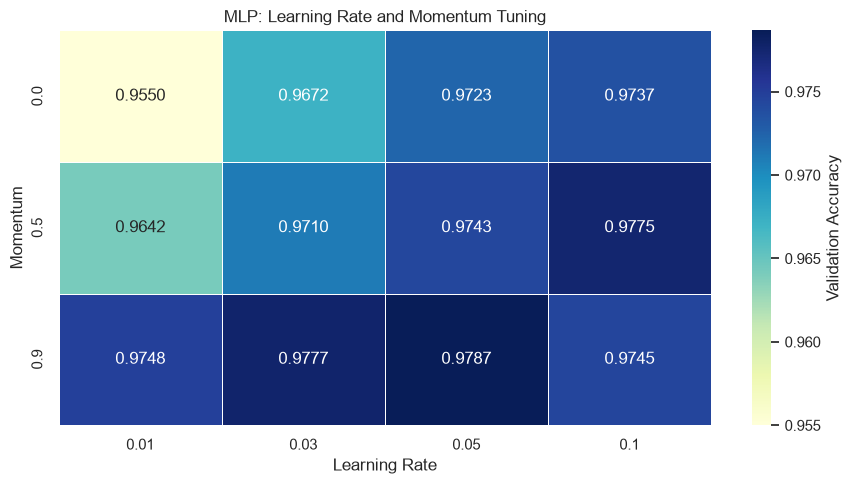

In [7]:
def plot_optimizer_heatmap(results_df):
    """Vẽ Heatmap Learning Rate và Momentum."""

    table = results_df.pivot(
        index="momentum",
        columns="lr",
        values="val_accuracy"
    )

    fig, ax = plt.subplots(figsize=(9, 5))

    sns.heatmap(
        table,
        annot=True,
        fmt=".4f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "Validation Accuracy"},
        ax=ax
    )

    ax.set_xlabel("Learning Rate")
    ax.set_ylabel("Momentum")
    ax.set_title("MLP: Learning Rate and Momentum Tuning")

    plt.tight_layout()
    plt.show()


plot_optimizer_heatmap(optimizer_df)

## 2. Tuning Network Architecture

Mục tiêu: Đánh giá ảnh hưởng của số lượng hidden layers
và hidden neurons đến hiệu năng của MLP.

Các kiến trúc được khảo sát:

1. 784-500-10
2. 784-128-10
3. 784-256-10
4. 784-256-128-10

Giữ cố định Learning Rate và Momentum được chọn
từ giai đoạn trước.

Không sử dụng Dropout hoặc Weight Decay.

Mỗi kiến trúc được huấn luyện trong 10 epochs.

Tiêu chí lựa chọn: Validation Accuracy.

In [8]:
architecture_results = []

for sizes in ARCH_GRID:

    model, history, train_time = train_mlp(
        sizes=sizes,
        lr=best_lr,
        momentum=best_momentum,
        epochs=EPOCHS_ARCH
    )

    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]
    val_loss = history["val_loss"][-1]

    if not np.isfinite(val_loss):
        val_acc = np.nan
        val_loss = np.nan

    architecture_name = "-".join(map(str, sizes))

    architecture_results.append({
        "sizes": sizes,
        "architecture": architecture_name,
        "n_params": model.n_params(),
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "train_time": train_time
    })

    print(
        f"Architecture: {architecture_name:<20} | "
        f"Parameters: {model.n_params():<8} | "
        f"Val Acc: {val_acc:.4f}"
    )


architecture_df = pd.DataFrame(architecture_results)

valid_arch_df = architecture_df.dropna(
    subset=["val_accuracy", "val_loss"]
)

if valid_arch_df.empty:
    raise RuntimeError("Không có kiến trúc MLP hợp lệ.")

best_arch_result = valid_arch_df.sort_values(
    by=["val_accuracy", "val_loss"],
    ascending=[False, True]
).iloc[0]

best_sizes = best_arch_result["sizes"]

print("\n=== BEST ARCHITECTURE ===")
print("Sizes:", best_sizes)
print("Parameters:", best_arch_result["n_params"])
print(f"Validation Accuracy: {best_arch_result['val_accuracy']:.4f}")

Architecture: 784-500-10           | Parameters: 397510   | Val Acc: 0.9822
Architecture: 784-128-10           | Parameters: 101770   | Val Acc: 0.9787
Architecture: 784-256-10           | Parameters: 203530   | Val Acc: 0.9792
Architecture: 784-256-128-10       | Parameters: 235146   | Val Acc: 0.9798

=== BEST ARCHITECTURE ===
Sizes: [784, 500, 10]
Parameters: 397510
Validation Accuracy: 0.9822


### Biểu đồ 2. Architecture Comparison

Sử dụng Grouped Bar Chart để so sánh Training Accuracy
và Validation Accuracy của từng kiến trúc.

- Trục X: Kiến trúc MLP.
- Trục Y: Accuracy.
- Hai nhóm cột: Training và Validation.

Số lượng tham số của mỗi mô hình được hiển thị
bên dưới tên kiến trúc.

Biểu đồ giúp đánh giá tác động của độ rộng và độ sâu
mạng đến hiệu quả phân loại.

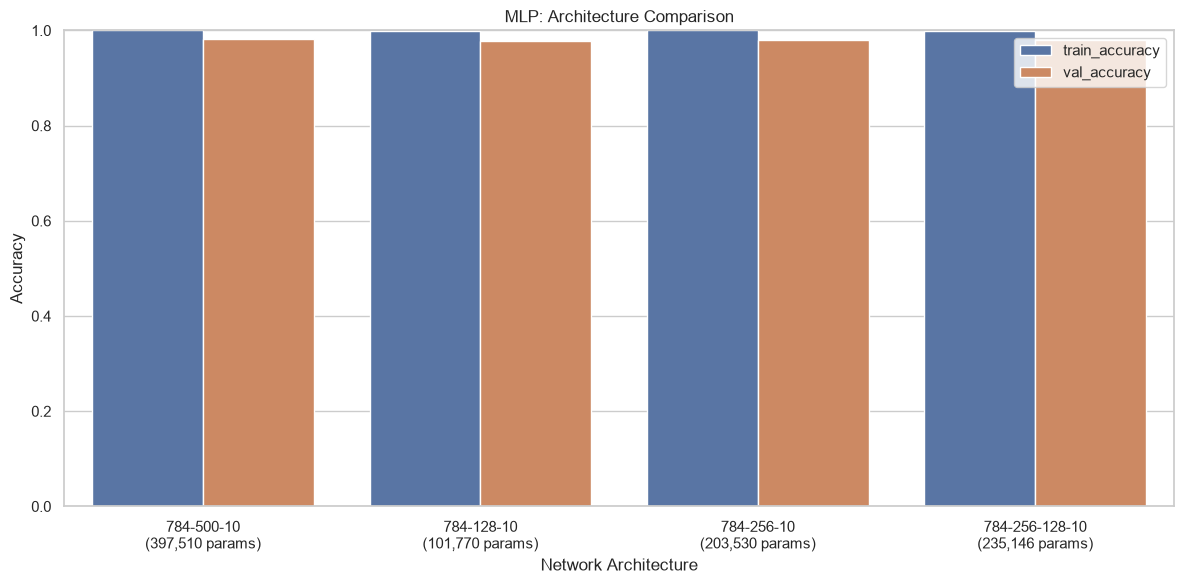

In [9]:
def plot_architecture_comparison(results_df):
    """So sánh Accuracy giữa các kiến trúc MLP."""

    plot_df = results_df.copy()

    plot_df["Architecture"] = [
        f"{name}\n({n_params:,} params)"
        for name, n_params in zip(
            plot_df["architecture"],
            plot_df["n_params"]
        )
    ]

    plot_df = plot_df.melt(
        id_vars="Architecture",
        value_vars=["train_accuracy", "val_accuracy"],
        var_name="Dataset",
        value_name="Accuracy"
    )

    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=plot_df,
        x="Architecture",
        y="Accuracy",
        hue="Dataset",
        ax=ax
    )

    ax.set_xlabel("Network Architecture")
    ax.set_ylabel("Accuracy")
    ax.set_title("MLP: Architecture Comparison")
    ax.set_ylim(0, 1)

    ax.legend(title="")

    plt.tight_layout()
    plt.show()


plot_architecture_comparison(architecture_df)

## 3. Tuning Regularization

Mục tiêu: Đánh giá tác động của Dropout và
L2 Regularization đến khả năng tổng quát hóa.

Dropout:
- 0.0
- 0.2
- 0.4

Weight Decay:
- 0.0
- 1e-4
- 1e-3

Tổng cộng: 3 × 3 = 9 cấu hình.

Sử dụng kiến trúc, Learning Rate và Momentum
đã lựa chọn ở các giai đoạn trước.

Mỗi cấu hình được huấn luyện tối đa 30 epochs,
sử dụng Early Stopping với patience = 6.

Tiêu chí lựa chọn: Validation Accuracy.

In [10]:
regularization_results = []

for p_drop in DROPOUT_GRID:
    for weight_decay in WEIGHT_DECAY_GRID:

        model, history, train_time = train_mlp(
            sizes=best_sizes,
            lr=best_lr,
            momentum=best_momentum,
            p_drop=p_drop,
            weight_decay=weight_decay,
            epochs=EPOCHS_REG,
            patience=PATIENCE
        )

        # Bỏ qua cấu hình không có epoch hợp lệ
        if model.best_epoch_ is None:
            print(
                f"Bỏ qua p_drop={p_drop}, "
                f"weight_decay={weight_decay}"
            )
            continue

        # Model đã khôi phục trọng số của best epoch
        y_pred = model.predict(X_val).cpu().numpy()

        metrics = ClassificationMetrics(
            np.asarray(y_val),
            y_pred,
            labels=LABELS
        ).evaluate()

        regularization_results.append({
            "p_drop": p_drop,
            "weight_decay": weight_decay,
            "val_accuracy": metrics["accuracy"],
            "macro_f1": metrics["macro_f1"],
            "best_epoch": model.best_epoch_,
            "train_time": train_time
        })

        print(
            f"Dropout={p_drop:<3} | "
            f"Weight Decay={weight_decay:<6} | "
            f"Val Acc={metrics['accuracy']:.4f} | "
            f"F1={metrics['macro_f1']:.4f}"
        )


regularization_df = pd.DataFrame(regularization_results)

if regularization_df.empty:
    raise RuntimeError("Không có cấu hình regularization hợp lệ.")

best_regularization = regularization_df.sort_values(
    by=["val_accuracy", "macro_f1"],
    ascending=[False, False]
).iloc[0]

best_p_drop = float(best_regularization["p_drop"])
best_weight_decay = float(best_regularization["weight_decay"])

print("\n=== BEST REGULARIZATION ===")
print(f"Dropout: {best_p_drop}")
print(f"Weight Decay: {best_weight_decay}")
print(f"Validation Accuracy: {best_regularization['val_accuracy']:.4f}")

Dropout=0.0 | Weight Decay=0.0    | Val Acc=0.9820 | F1=0.9819
Dropout=0.0 | Weight Decay=0.0001 | Val Acc=0.9825 | F1=0.9824
Dropout=0.0 | Weight Decay=0.001  | Val Acc=0.9790 | F1=0.9789
Dropout=0.2 | Weight Decay=0.0    | Val Acc=0.9783 | F1=0.9782
Dropout=0.2 | Weight Decay=0.0001 | Val Acc=0.9805 | F1=0.9804
Dropout=0.2 | Weight Decay=0.001  | Val Acc=0.9797 | F1=0.9796
Dropout=0.4 | Weight Decay=0.0    | Val Acc=0.9783 | F1=0.9782
Dropout=0.4 | Weight Decay=0.0001 | Val Acc=0.9813 | F1=0.9813
Dropout=0.4 | Weight Decay=0.001  | Val Acc=0.9792 | F1=0.9790

=== BEST REGULARIZATION ===
Dropout: 0.0
Weight Decay: 0.0001
Validation Accuracy: 0.9825


### Biểu đồ 3. Dropout × Weight Decay Heatmap

Sử dụng Heatmap để trực quan hóa ảnh hưởng của
hai phương pháp regularization.

- Trục X: Weight Decay.
- Trục Y: Dropout.
- Màu sắc: Validation Accuracy.

Biểu đồ giúp xác định liệu Dropout và L2
có cải thiện khả năng tổng quát hóa của MLP hay không.

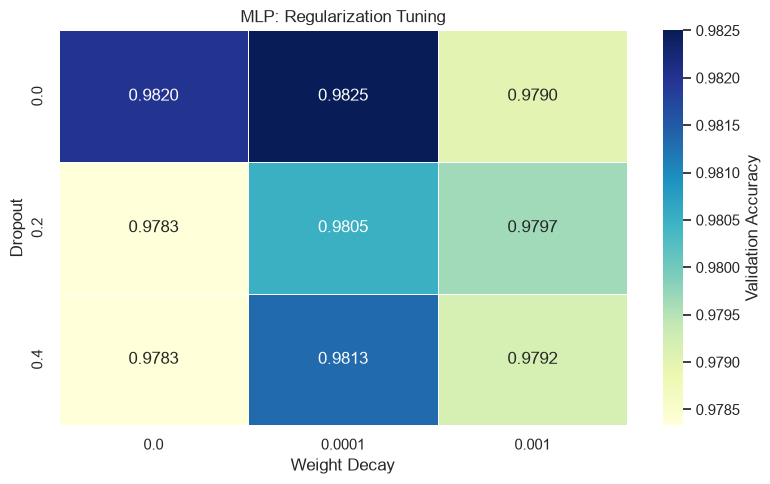

In [11]:
def plot_regularization_heatmap(results_df):
    """Vẽ Heatmap Dropout và Weight Decay."""

    table = results_df.pivot(
        index="p_drop",
        columns="weight_decay",
        values="val_accuracy"
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    sns.heatmap(
        table,
        annot=True,
        fmt=".4f",
        cmap="YlGnBu",
        linewidths=0.5,
        cbar_kws={"label": "Validation Accuracy"},
        ax=ax
    )

    ax.set_xlabel("Weight Decay")
    ax.set_ylabel("Dropout")
    ax.set_title("MLP: Regularization Tuning")

    plt.tight_layout()
    plt.show()


plot_regularization_heatmap(regularization_df)

## 4. Baseline vs Tuned MLP

Sau khi hoàn thành ba giai đoạn tuning,
tiến hành huấn luyện lại hai mô hình:

1. Baseline MLP.
2. Tuned MLP.

Cả hai mô hình được huấn luyện từ đầu với:

- Max Epochs = 40.
- Batch Size = 128.
- Patience = 6.
- Seed = 42.

Mục tiêu là so sánh hiệu năng của mô hình
trước và sau khi tinh chỉnh hyperparameters.

Đánh giá dựa trên Validation Accuracy và Macro F1.

In [12]:
# Baseline MLP
baseline_model, baseline_history, baseline_time = train_mlp(
    sizes=MLP_BASELINE["sizes"],
    lr=MLP_BASELINE["lr"],
    momentum=MLP_BASELINE["momentum"],
    p_drop=MLP_BASELINE["p_drop"],
    weight_decay=MLP_BASELINE["weight_decay"],
    epochs=EPOCHS_FINAL,
    patience=PATIENCE
)

# Tuned MLP
best_model, best_history, best_time = train_mlp(
    sizes=best_sizes,
    lr=best_lr,
    momentum=best_momentum,
    p_drop=best_p_drop,
    weight_decay=best_weight_decay,
    epochs=EPOCHS_FINAL,
    patience=PATIENCE
)

print("=== BASELINE MLP ===")
print("Best Epoch:", baseline_model.best_epoch_)
print(f"Training Time: {baseline_time:.2f} seconds")

print("\n=== TUNED MLP ===")
print("Architecture:", best_sizes)
print("Learning Rate:", best_lr)
print("Momentum:", best_momentum)
print("Dropout:", best_p_drop)
print("Weight Decay:", best_weight_decay)
print("Best Epoch:", best_model.best_epoch_)
print(f"Training Time: {best_time:.2f} seconds")

=== BASELINE MLP ===
Best Epoch: 5
Training Time: 10.36 seconds

=== TUNED MLP ===
Architecture: [784, 500, 10]
Learning Rate: 0.05
Momentum: 0.9
Dropout: 0.0
Weight Decay: 0.0001
Best Epoch: 37
Training Time: 57.33 seconds


## 5. Performance Evaluation

Sử dụng ClassificationMetrics tự cài đặt để đánh giá
Baseline và Tuned MLP trên validation set.

Các metrics được sử dụng:

- Accuracy.
- Macro F1.
- Training Time.
- Best Epoch.

Kết quả được trình bày dưới dạng bảng để dễ so sánh.

In [13]:
# Dự đoán trên validation set
baseline_pred = baseline_model.predict(X_val).numpy()
best_pred = best_model.predict(X_val).numpy()

# Tính metrics cho Baseline
baseline_metrics = ClassificationMetrics(
    np.asarray(y_val),
    baseline_pred,
    labels=LABELS
).evaluate()

# Tính metrics cho Tuned MLP
best_metrics = ClassificationMetrics(
    np.asarray(y_val),
    best_pred,
    labels=LABELS
).evaluate()

# Bảng so sánh
comparison_df = pd.DataFrame({
    "Model": ["Baseline MLP", "Tuned MLP"],
    "Accuracy": [
        baseline_metrics["accuracy"],
        best_metrics["accuracy"]
    ],
    "Macro F1": [
        baseline_metrics["macro_f1"],
        best_metrics["macro_f1"]
    ],
    "Best Epoch": [
        baseline_model.best_epoch_,
        best_model.best_epoch_
    ],
    "Train Time (s)": [
        baseline_time,
        best_time
    ]
})

print("=== BASELINE VS TUNED MLP ===")
print(comparison_df.to_string(index=False))

=== BASELINE VS TUNED MLP ===
       Model  Accuracy  Macro F1  Best Epoch  Train Time (s)
Baseline MLP  0.978000  0.977792           5       10.363776
   Tuned MLP  0.982667  0.982596          37       57.328322


### Biểu đồ 4. Learning Curves

Trực quan hóa quá trình huấn luyện của Baseline và Tuned MLP.

Biểu đồ gồm bốn phần:

1. Baseline - Training Loss và Validation Loss.
2. Tuned - Training Loss và Validation Loss.
3. Baseline - Training Accuracy và Validation Accuracy.
4. Tuned - Training Accuracy và Validation Accuracy.

Đánh dấu epoch có Validation Loss nhỏ nhất.

Mục tiêu:

- Phân tích tốc độ hội tụ.
- Phát hiện Overfitting hoặc Underfitting.
- Đánh giá hiệu quả của Early Stopping.
- So sánh quá trình học trước và sau tuning.

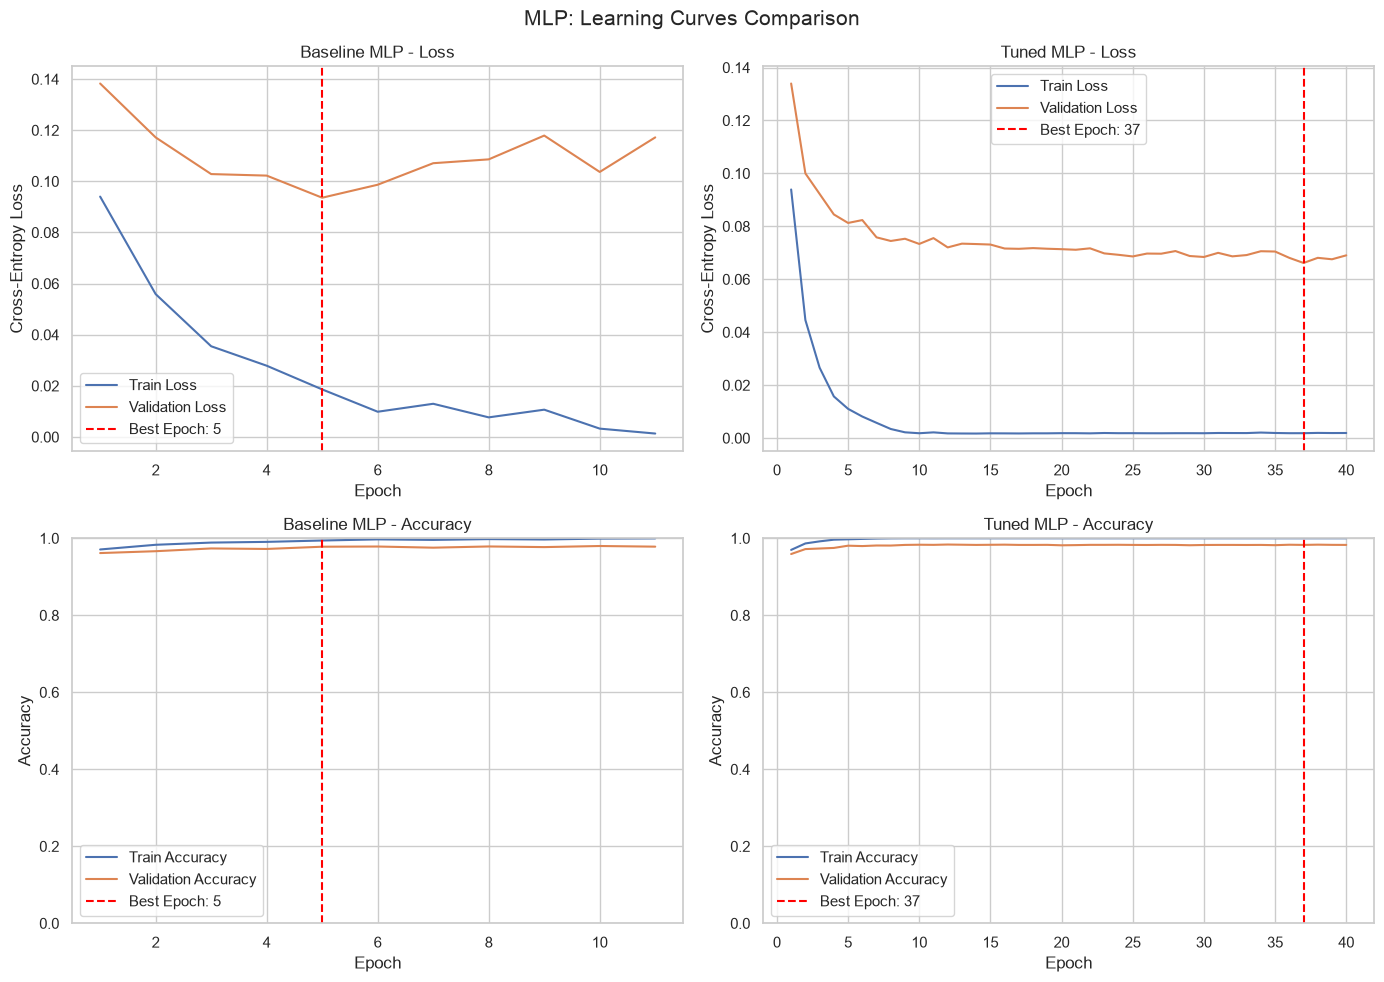

In [14]:
def plot_learning_curves(baseline_history, best_history):
    """So sánh Learning Curves của Baseline và Tuned MLP."""

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    histories = [baseline_history, best_history]
    models = [baseline_model, best_model]
    titles = ["Baseline MLP", "Tuned MLP"]

    for col, (history, model, title) in enumerate(
        zip(histories, models, titles)
    ):
        epochs = np.arange(1, len(history["train_loss"]) + 1)

        # Biểu đồ Loss
        sns.lineplot(
            x=epochs,
            y=history["train_loss"],
            label="Train Loss",
            ax=axes[0, col]
        )

        sns.lineplot(
            x=epochs,
            y=history["val_loss"],
            label="Validation Loss",
            ax=axes[0, col]
        )

        axes[0, col].set_title(f"{title} - Loss")
        axes[0, col].set_xlabel("Epoch")
        axes[0, col].set_ylabel("Cross-Entropy Loss")

        # Biểu đồ Accuracy
        sns.lineplot(
            x=epochs,
            y=history["train_acc"],
            label="Train Accuracy",
            ax=axes[1, col]
        )

        sns.lineplot(
            x=epochs,
            y=history["val_acc"],
            label="Validation Accuracy",
            ax=axes[1, col]
        )

        axes[1, col].set_title(f"{title} - Accuracy")
        axes[1, col].set_xlabel("Epoch")
        axes[1, col].set_ylabel("Accuracy")
        axes[1, col].set_ylim(0, 1)

        # Đánh dấu Best Epoch
        if model.best_epoch_ is not None:
            for row in range(2):
                axes[row, col].axvline(
                    model.best_epoch_,
                    color="red",
                    linestyle="--",
                    label=f"Best Epoch: {model.best_epoch_}"
                )

        axes[0, col].legend()
        axes[1, col].legend()

    fig.suptitle("MLP: Learning Curves Comparison", fontsize=15)

    plt.tight_layout()
    plt.show()


plot_learning_curves(
    baseline_history,
    best_history
)

### Biểu đồ 5. Confusion Matrix Comparison

So sánh Confusion Matrix của Baseline và Tuned MLP.

Sử dụng Normalized Confusion Matrix:

- Hàng: Nhãn thực tế.
- Cột: Nhãn dự đoán.
- Giá trị: Tỷ lệ dự đoán tương ứng.

Mục tiêu:

- Xác định các chữ số dễ nhầm lẫn.
- Phân tích lỗi phân loại.
- Quan sát sự thay đổi sau tuning.

Confusion Matrix được tính bằng ClassificationMetrics
đã tự cài đặt.

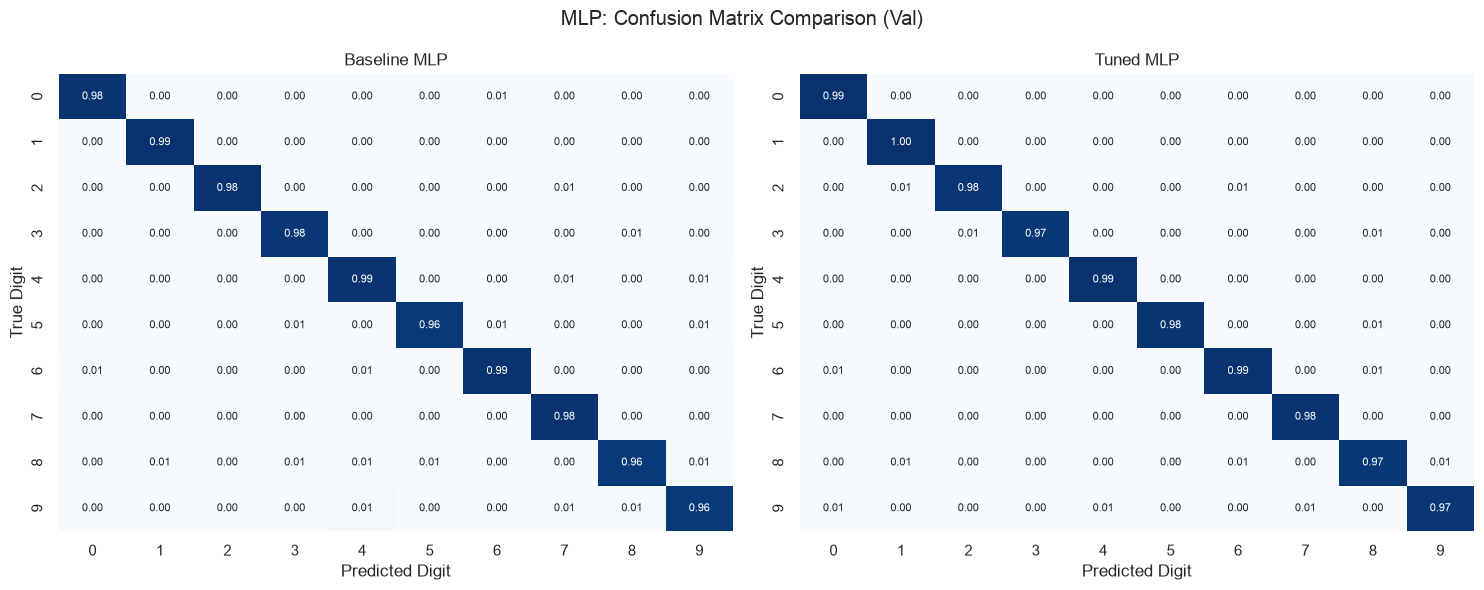

In [15]:
def plot_confusion_matrices(y_val, baseline_pred, best_pred):
    """So sánh Confusion Matrix trước và sau tuning."""

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    predictions = [baseline_pred, best_pred]
    titles = ["Baseline MLP", "Tuned MLP"]

    for ax, pred, title in zip(axes, predictions, titles):

        metrics = ClassificationMetrics(
            np.asarray(y_val),
            pred,
            labels=LABELS
        )

        cm, labels = metrics.get_confustion_matrix()

        # Chuẩn hóa theo từng hàng
        row_sum = cm.sum(axis=1, keepdims=True)

        cm_normalized = np.divide(
            cm,
            row_sum,
            out=np.zeros_like(cm, dtype=float),
            where=row_sum != 0
        )

        sns.heatmap(
            cm_normalized,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            vmin=0,
            vmax=1,
            xticklabels=labels,
            yticklabels=labels,
            annot_kws={"size": 8},
            cbar=False,
            ax=ax
        )

        ax.set_title(title)
        ax.set_xlabel("Predicted Digit")
        ax.set_ylabel("True Digit")

    fig.suptitle("MLP: Confusion Matrix Comparison (Val)")

    plt.tight_layout()
    plt.show()


plot_confusion_matrices(
    y_val,
    baseline_pred,
    best_pred
)

### Biểu đồ 6. Per-Class Recall Comparison

So sánh Recall của từng chữ số từ 0 đến 9
trước và sau khi tuning.

- Trục X: Digit.
- Trục Y: Recall.
- Hai nhóm cột: Baseline và Tuned.

Mục tiêu:

- Xác định chữ số được cải thiện sau tuning.
- Xác định chữ số có Recall giảm.
- Đánh giá tính đồng đều của mô hình trên các lớp.

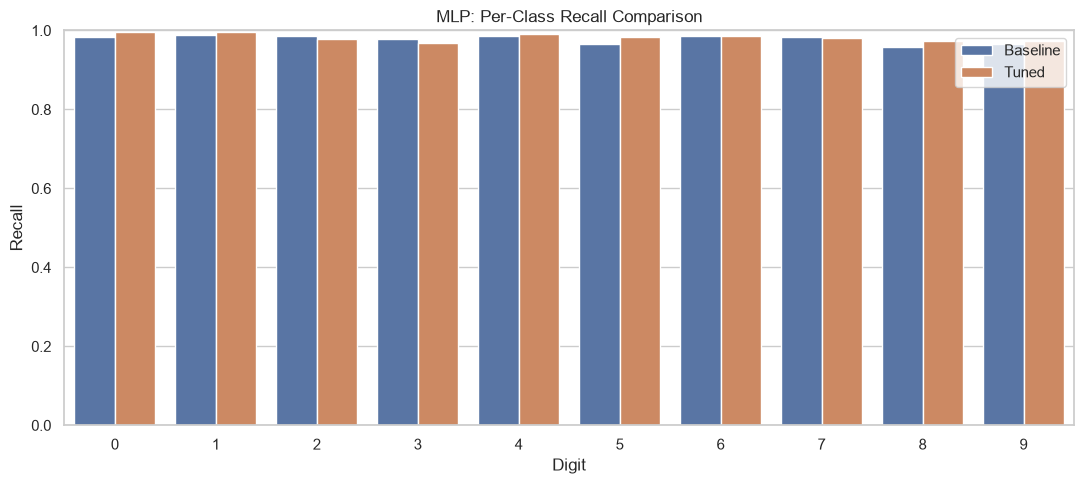

In [16]:
def plot_per_class_recall(baseline_metrics, best_metrics):
    """So sánh Recall từng lớp của Baseline và Tuned MLP."""

    baseline_recall = baseline_metrics["recall"]
    best_recall = best_metrics["recall"]

    plot_data = pd.DataFrame({
        "Digit": list(LABELS) * 2,
        "Recall": list(baseline_recall) + list(best_recall),
        "Model": ["Baseline"] * 10 + ["Tuned"] * 10
    })

    fig, ax = plt.subplots(figsize=(11, 5))

    sns.barplot(
        data=plot_data,
        x="Digit",
        y="Recall",
        hue="Model",
        ax=ax
    )

    ax.set_xlabel("Digit")
    ax.set_ylabel("Recall")
    ax.set_title("MLP: Per-Class Recall Comparison")
    ax.set_ylim(0, 1)
    ax.legend(title="")

    plt.tight_layout()
    plt.show()


plot_per_class_recall(
    baseline_metrics,
    best_metrics
)

## 6. Hyperparameter Tuning Summary

Tổng hợp các hyperparameters được lựa chọn
sau ba giai đoạn tuning.

Báo cáo:

- Network Architecture.
- Learning Rate.
- Momentum.
- Dropout.
- Weight Decay.
- Batch Size.
- Max Epochs.
- Patience.

Các giá trị này được sử dụng cho Tuned MLP
trong thí nghiệm đánh giá cuối cùng.

In [17]:
best_config = {
    "sizes": best_sizes,
    "lr": best_lr,
    "momentum": best_momentum,
    "p_drop": best_p_drop,
    "weight_decay": best_weight_decay,
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS_FINAL,
    "patience": PATIENCE
}

print("=== BEST MLP HYPERPARAMETERS ===")

for parameter, value in best_config.items():
    print(f"{parameter:<15}: {value}")

print("\n=== PERFORMANCE COMPARISON ===")
print(comparison_df.to_string(index=False))

=== BEST MLP HYPERPARAMETERS ===
sizes          : [784, 500, 10]
lr             : 0.05
momentum       : 0.9
p_drop         : 0.0
weight_decay   : 0.0001
batch_size     : 128
max_epochs     : 40
patience       : 6

=== PERFORMANCE COMPARISON ===
       Model  Accuracy  Macro F1  Best Epoch  Train Time (s)
Baseline MLP  0.978000  0.977792           5       10.363776
   Tuned MLP  0.982667  0.982596          37       57.328322


## 7. Sử Dụng Best Model để dự đoán trên tập Test hoàn toàn chưa nhìn thấy

In [18]:
y_test_pred = best_model.predict(X_test)

ClassificationMetrics(y_pred=y_test_pred, y_true=y_test).report()

     Class  Precision     Recall         F1
         0      0.981      0.994      0.987 
         1      0.993      0.991      0.992 
         2      0.982      0.980      0.981 
         3      0.981      0.985      0.983 
         4      0.985      0.981      0.983 
         5      0.983      0.979      0.981 
         6      0.986      0.984      0.985 
         7      0.981      0.982      0.981 
         8      0.982      0.980      0.981 
         9      0.981      0.978      0.980 
 Macro avg      0.983      0.983      0.983 

Accuracy: 0.984


## 8. Lưu Tham số Model

In [19]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Saving model to: {MODELS_DIR.absolute()}")

mlp_save_path = MODELS_DIR / "mlp_model.pth"

mlp_checkpoint = {
    "model_state_dict": best_model.model.state_dict(),

    "config": {
        **best_config, # luu toàn bộ trọng số
        "activation": "relu",
        "init": "he",
        "seed": 42,
    },

    "history": best_model.history_,
    "best_epoch": getattr(best_model, "best_epoch_", None),
}

torch.save(mlp_checkpoint, mlp_save_path)

print(f"MLP saved successfully: {mlp_save_path}")

Saving model to: /home/nguyenhaianh/Desktop/Classify_Number/models
MLP saved successfully: /home/nguyenhaianh/Desktop/Classify_Number/models/mlp_model.pth
